# Домашнее задание по теме «Линейная регрессия»

В этом задании ты обучишь линейную регрессию, применишь регуляризацию, нормировку, проанализируешь качество модели, а также реализуешь градиентный спуск.

## Подготовка

In [1]:
import gc

import pandas as pd
import numpy as np

import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import time
from tqdm import tqdm

from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler

##  Задача 1 [0,5 балла]

Объясни, почему при использовании регуляризации штрафуются только веса, но не свободный коэффициент $w_0$ (другое обозначение — $b$)?

Напомним, что предсказание линейной модели считается по формуле:

$$a(x) = \langle w, x \rangle + w_0.$$

**Напиши ответ здесь:**

Большой b сам по себе чувствительности не создаёт: он просто сдвигает все предсказания на одну величину.
Например, мы предсказываем зарплату в рублях. Средняя зарплата 100 000, поэтому большой будет большой b. Штрафовать его означает тянуть базовый прогноз к нулю, хотя нулевая зарплата здесь не имеет особого смысла.

-------

Для следующих заданий возьми данные из датасета [Predict Calorie Expenditure](https://www.kaggle.com/competitions/playground-series-s5e5/overview).

Цель соревнования — предсказать, сколько калорий потратит человек за тренировку по признаковому описанию как человека, так и самой тренировки.

In [2]:
! gdown 1jb1tbxmGcgFk-jzNgu-sHXCUkgtAslRq

Downloading...
From: https://drive.google.com/uc?id=1jb1tbxmGcgFk-jzNgu-sHXCUkgtAslRq
To: /content/train.csv
100% 35.5M/35.5M [00:01<00:00, 27.9MB/s]


In [3]:
data = pd.read_csv("/content/train.csv", index_col=0)
data.head()

,Sex,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
id,,,,,,,,
0,male,36,189.0,82.0,26.0,101.0,41.0,150.0
1,female,64,163.0,60.0,8.0,85.0,39.7,34.0
2,female,51,161.0,64.0,7.0,84.0,39.8,29.0
3,male,20,192.0,90.0,25.0,105.0,40.7,140.0
4,female,38,166.0,61.0,25.0,102.0,40.6,146.0


В таблице 8 столбцов: категориальный признак `Sex`, 6 числовых признаков и целевая переменная `Calories`.

Разделим данные на признаки и таргет, затем на `train` и `val`. В этой работе `val` используется для сравнения и выбора вариантов модели. Отдельный итоговый тест здесь не выделяем.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(data.drop('Calories', axis=1), data['Calories'], test_size=0.25, random_state=123)

## Задача 2. OneHotEncoder [0,5 балла]

В семинаре мы использовали `Target Encoding` для приведения категориальных переменных к числовому виду, так как в задаче было очень много категорий. Но для линейных моделей обычно используется `OneHotEncoding`.

Примени [OneHotEncoding из sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) к категориальной переменной и получи новый датасет, который уже будет использоваться для дальнейшего обучения моделей. Но не делай этого в явном виде. Задай последовательность действий в виде [пайплайна из sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html). Он тебе пригодится в задачах.

Затраты по калориям не бывают отрицательными. Модель этого не знает, так как она предсказывает на всей числовой прямой. Поэтому нужно избежать отрицательных значений на этапе вызова `predict` с помощью [TransformedTargetRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html).

Сделать неотрицательными предсказания калорий можно по-разному: округлить до нуля, взять минимальное по обучающей выборке.

**Задание**:
1. Преобразуй датасет к числовому виду.
2. Обучи модель линейной регрессии и сделай предсказание на валидации, чтобы проверить, что всё работает.
3. Добавь постобработку ответов.
4. Оберни все в Pipeline.

In [5]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor

def identity(y):
    return y

def postprocessing(y):
    return np.maximum(y, 0)

preprocessor = ColumnTransformer(
    transformers = [
        ("Sex", OneHotEncoder(drop="first", handle_unknown="ignore"), ["Sex"])
    ],
    remainder="passthrough"
)

model = TransformedTargetRegressor(
    regressor=LinearRegression(),
    func=identity,
    inverse_func=postprocessing,
    check_inverse=False
)

pipe = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_val)


#print(y_pred.min())


##  Задача 3. Добавь функцию оценки качества работы [0,5 балла]

В соревновании используется не самая стандартная метрика RMSLE (англ. Root Mean Squared Logarithmic Error).

$$RMSLE = \Big(\frac{1}{n}\sum_{i=1}^n(\log{(1+\hat y_i)} - \log{(1+y_i)})^{2}\Big)^{\frac{1}{2}}$$

Эта метрика есть в реализации [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_log_error.html), но тебе нужно написать её самостоятельно, чтобы в следующих заданиях её можно было передавать внутрь пайплайна через [make_scorer](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.make_scorer.html).

Подумай, с каким знаком должна возвращать ответ эта функция для корректной работы `make_scorer`.

**Задание:**
1. Реализуй функцию для подсчёта метрики.
2. Проверь, что она работает корректно (сравни с примером из sklearn).
3. Оцени качество предсказаний на `train` и `val`.
4. Занеси положительную RMSLE в таблицу с историей. Используй единое имя `scoring_foo(y_true, y_pred)` для скоринговой функции во всех следующих заданиях. В `make_scorer` используется соглашение «больше — лучше», а в таблице RMSLE «меньше — лучше».

In [6]:
from sklearn.metrics import root_mean_squared_log_error

def scoring_foo(y_true, y_pred): # Это имя используется и в следующих заданиях
  y_true = np.asarray(y_true)
  y_pred = np.asarray(y_pred)
  
  squared_log_error = (np.log1p(y_pred) - np.log1p(y_true))**2
  return -np.sqrt(np.mean(squared_log_error))

# Получи предсказания на train
y_pred_train = pipe.predict(X_train)
y_pred_val = pipe.predict(X_val)

# Сравни ответы для валидации
print(scoring_foo(y_val, y_pred_val))
print(root_mean_squared_log_error(y_val, y_pred_val))

# Получи оценку метрики для train и val
rmsle_train = -scoring_foo(y_train, y_pred_train)
rmsle_valid = -scoring_foo(y_val, y_pred_val)

# Создай контейнер для хранения информации о метриках
res = {}

# Запиши метрики в контейнер и выведи таблицу
res['base'] = [rmsle_train, rmsle_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmsle_train', 'rmsle_valid'])
df_res

-0.5673800814097045
0.5673800814097045


,rmsle_train,rmsle_valid
base,0.564621,0.56738


##  Задача 4. Выбери модель и нормализацию [1 балл]

Используй модели:
* Ridge,
* Lasso,
* ElasticNet.

Для их качественной работы примени нормировки:
* MinMaxScaler,
* StandardScaler,
* RobustScaler.

**Задание.**
Оцени качество работы каждой пары нормировка — модель и занеси результаты в таблицу с соответствующим названием. По названию должно быть понятно, к какой комбинации относится результат.

Нормировку добавь внутрь пайплайна. За основу возьми пайплайн из задания выше.

In [7]:
from sklearn.linear_model import Ridge, ElasticNet, Lasso
from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler
from sklearn.base import clone

scalers = [MinMaxScaler, StandardScaler, RobustScaler]
regressors = [Ridge, Lasso, ElasticNet]
trained_pipes = {}

for scaler_class in scalers:
    for regressor_class in regressors:
        wrapped_model = clone(model)
        wrapped_model.set_params(regressor=regressor_class())

        experiment_pipe = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("scaler", scaler_class()),
            ("model", wrapped_model),
        ])

        experiment_pipe.fit(X_train, y_train)
        pred_train = experiment_pipe.predict(X_train)
        pred_val = experiment_pipe.predict(X_val)

        name = f"{scaler_class.__name__}_{regressor_class.__name__}"
        res[name] = [
            -scoring_foo(y_train, pred_train),
            -scoring_foo(y_val, pred_val),
        ]
        trained_pipes[name] = experiment_pipe

best_name = min(trained_pipes, key=lambda name: res[name][1])
pipe = trained_pipes[best_name]
print("Лучшая комбинация:", best_name)

df_res = pd.DataFrame.from_dict(
    res, orient='index', columns=['rmsle_train', 'rmsle_valid']
)
df_res.sort_values('rmsle_valid')


Лучшая комбинация: RobustScaler_ElasticNet


,rmsle_train,rmsle_valid
RobustScaler_ElasticNet,0.446483,0.446361
StandardScaler_ElasticNet,0.448930,0.448114
MinMaxScaler_Lasso,0.469986,0.468928
MinMaxScaler_Ridge,0.564590,0.567345
RobustScaler_Ridge,0.564620,0.567379
StandardScaler_Ridge,0.564620,0.567380
base,0.564621,0.567380
StandardScaler_Lasso,0.573146,0.573873
RobustScaler_Lasso,0.576662,0.577741
MinMaxScaler_ElasticNet,0.898406,0.898806


## Задача 5. Добавь полиномы [1 балл]



Линейная модель может решать нелинейные задачи, если к признаковому пространству добавить их полиномы. Вряд ли сожжённые за тренировку калории линейно зависят от признаков. Поэтому добавь полиномы различных степеней к признаковому пространству, чтобы улучшить качество решения задачи.

В этом тебе поможет класс [PolynomialFeatures](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html), он также интегрируется в пайплайн решения. Подумай, куда конкретно его вставлять в пайплайн и нужно ли добавлять полиномы OHE переменных.

Обязательно изучи документацию: там есть один аргумент, который тебе надо выключить.

Для добавления полиномов руководствуйся логикой или общими знаниями. Например, в экономических и социологических исследованиях часто добавляют к данным переменную «квадрат возраста». Её логика в следующем: человек растёт и развивается до определённого возраста, а далее угасает. Скорее всего, целевая переменная и возраст будут зависеть параболически, «квадрат возраста» позволит учесть эту параболическую зависимость.

Если не можешь придумать полиномы, то перебери переменные и значения полиномов для них. Переменных не так много, а модель учится быстро.

**Задание:**
1. Возьми лучшую по валидации комбинацию нормировка — модель.
2. Добавь к пайплайну полиномы для некоторых переменных.
3. Сохрани результат лучшего эксперимента в таблицу (у авторов задания получилось качество 0.238208).
4. Опиши, как выбирал полиномы.

degree=1: train=0.446483, val=0.446361
degree=2: train=0.389856, val=0.388816
degree=3: train=0.313038, val=0.310959
degree=4: train=0.243832, val=0.240839


,degree,n_features,rmsle_train,rmsle_valid
0,4,72,0.243832,0.240839
1,3,37,0.313038,0.310959
2,2,17,0.389856,0.388816
3,1,7,0.446483,0.446361


Лучшая степень: 4; модель и нормировка: RobustScaler_ElasticNet


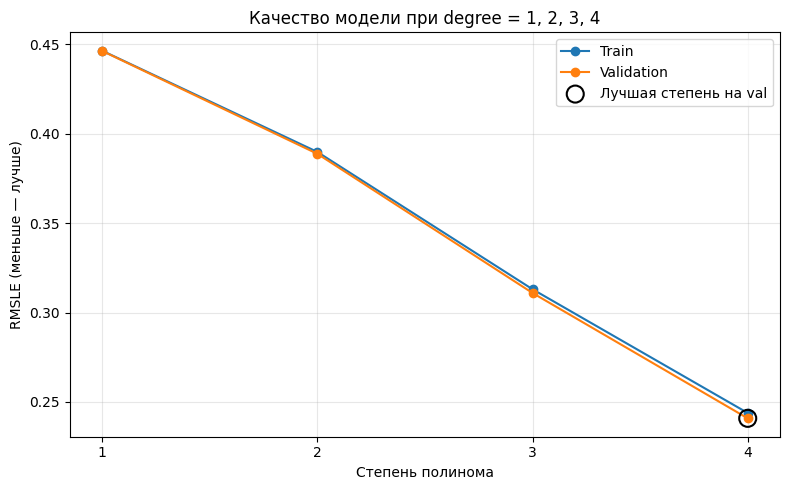

In [8]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.base import clone
from IPython.display import display

poly_columns = ["Age", "Duration", "Body_Temp", "Heart_Rate"]
poly_degrees = [1, 2, 3, 4]

base_pipe = trained_pipes[best_name]
poly_pipes = {}
poly_results = []

for degree in poly_degrees:
    poly_preprocessor = ColumnTransformer(
        transformers=[
            (
                "Sex",
                OneHotEncoder(drop="first", handle_unknown="ignore"),
                ["Sex"],
            ),
            (
                "poly",
                PolynomialFeatures(degree=degree, include_bias=False),
                poly_columns,
            ),
        ],
        remainder="passthrough",
    )

    candidate_pipe = Pipeline([
        ("preprocessor", poly_preprocessor),
        ("scaler", clone(base_pipe.named_steps["scaler"])),
        ("model", clone(base_pipe.named_steps["model"])),
    ])
    candidate_pipe.fit(X_train, y_train)

    rmsle_train = -scoring_foo(y_train, candidate_pipe.predict(X_train))
    rmsle_valid = -scoring_foo(y_val, candidate_pipe.predict(X_val))
    poly_pipes[degree] = candidate_pipe
    poly_results.append({
        "degree": degree,
        "n_features": len(poly_preprocessor.get_feature_names_out()),
        "rmsle_train": rmsle_train,
        "rmsle_valid": rmsle_valid,
    })
    res[f"poly_degree_{degree}"] = [rmsle_train, rmsle_valid]
    print(f"degree={degree}: train={rmsle_train:.6f}, val={rmsle_valid:.6f}")


df_poly = pd.DataFrame(poly_results).sort_values(
    ["rmsle_valid", "degree"]
).reset_index(drop=True)
display(df_poly.style.format({"rmsle_train": "{:.6f}", "rmsle_valid": "{:.6f}"}))

best_degree = int(df_poly.loc[0, "degree"])
pipe = poly_pipes[best_degree]
res["best_poly"] = [
    float(df_poly.loc[0, "rmsle_train"]),
    float(df_poly.loc[0, "rmsle_valid"]),
]
df_res = pd.DataFrame.from_dict(
    res, orient="index", columns=["rmsle_train", "rmsle_valid"]
)
print(f"Лучшая степень: {best_degree}; модель и нормировка: {best_name}")


plot_data = df_poly.sort_values("degree")
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(plot_data["degree"], plot_data["rmsle_train"], marker="o", label="Train")
ax.plot(plot_data["degree"], plot_data["rmsle_valid"], marker="o", label="Validation")
ax.scatter(
    [best_degree], [df_poly.loc[0, "rmsle_valid"]],
    s=150, facecolors="none", edgecolors="black", linewidths=1.5,
    label="Лучшая степень на val", zorder=5,
)
ax.set(
    xlabel="Степень полинома",
    ylabel="RMSLE (меньше — лучше)",
    title="Качество модели при degree = 1, 2, 3, 4",
    xticks=poly_degrees,
)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


In [9]:
# Историю храним в res: ключ — название эксперимента, значения — две метрики.
experiment_name = f"{best_name}_Poly_degree_{best_degree}"
res[experiment_name] = [
    float(df_poly.loc[0, "rmsle_train"]),
    float(df_poly.loc[0, "rmsle_valid"]),
]

# Обновляем общую таблицу из всей накопленной истории.
df_res = pd.DataFrame.from_dict(
    res, orient="index", columns=["rmsle_train", "rmsle_valid"]
)
df_res.sort_values("rmsle_valid")


,rmsle_train,rmsle_valid
RobustScaler_ElasticNet_Poly_degree_4,0.243832,0.240839
poly_degree_4,0.243832,0.240839
best_poly,0.243832,0.240839
poly_degree_3,0.313038,0.310959
poly_degree_2,0.389856,0.388816
poly_degree_1,0.446483,0.446361
RobustScaler_ElasticNet,0.446483,0.446361
StandardScaler_ElasticNet,0.448930,0.448114
MinMaxScaler_Lasso,0.469986,0.468928
MinMaxScaler_Ridge,0.564590,0.567345


Полиномы выбирал так, сначала посмотрел 2 степени для признаков ["Age", "Duration", "Body_Temp", "Heart_Rate"].

Кажется полезными признаки  duration * Body_Temp, а также квадарат от Age, duration * Heart_Rate.

Чтобы получил коэффицент age * Duration * Body_Temp * Heart_Rate, необходим полином 4ой степени. 

В цикле перебрал значения от 1 до 4 для проверки теории. 4 степень лучше всего себя показала.


##  Задача 6. Добавь дискретизацию [1 балл]

Некоторые вещественные признаки можно разбить на интервалы или дискретизовать. Для этого в sklearn есть функционал [KBinsDiscretizer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.KBinsDiscretizer.html). Примени его к переменным по своему усмотрению, чтобы улучшить качество.

**Задание:**
1. Добавь `KBinsDiscretizer` в пайплайн. Документация поможет тебе выбрать правильные аргументы.
2. Вынеси лучшее качество в таблицу с результатам (у авторов задания получилось 0.234339).

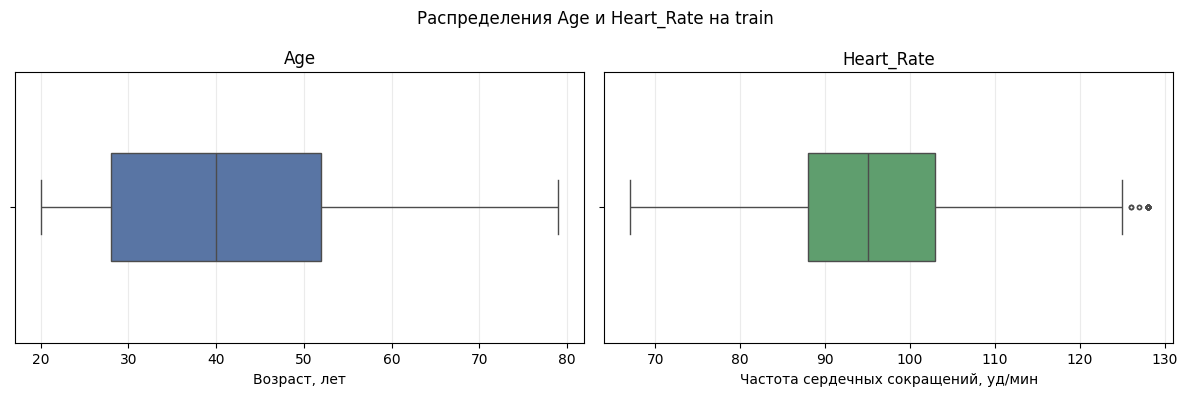

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, column, label, color in zip(
    axes,
    ["Age", "Heart_Rate"],
    ["Возраст, лет", "Частота сердечных сокращений, уд/мин"],
    ["#4C72B0", "#55A868"],
):
    sns.boxplot(
        x=X_train[column], ax=ax, color=color,
        width=0.4, whis=1.5, fliersize=3,
    )
    ax.set_title(column)
    ax.set_xlabel(label)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle("Распределения Age и Heart_Rate на train")
fig.tight_layout()
plt.show()


In [11]:
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import PolynomialFeatures
from sklearn.base import clone
from IPython.display import display

poly_degrees = 4
base_pipe = trained_pipes[best_name]

poly_preprocessor = ColumnTransformer(
    transformers=[
        (
            "Sex",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            ["Sex"],
        ),
        (
            "poly",
            PolynomialFeatures(degree=degree, include_bias=False),
            ["Age", "Duration", "Body_Temp", "Heart_Rate"],
        ),
        (
            "discretizer",
            KBinsDiscretizer(
                n_bins=5,
                strategy="quantile",
                encode="onehot-dense",
            ),
            ["Age", "Heart_Rate"],
        )
    ],
    remainder="passthrough",
)

candidate_pipe = Pipeline([
    ("preprocessor", poly_preprocessor),
    ("scaler", clone(base_pipe.named_steps["scaler"])),
    ("model", clone(base_pipe.named_steps["model"])),
])
candidate_pipe.fit(X_train, y_train)

rmsle_train = -scoring_foo(y_train, candidate_pipe.predict(X_train))
rmsle_valid = -scoring_foo(y_val, candidate_pipe.predict(X_val))

print(f"degree={degree}: train={rmsle_train:.6f}, val={rmsle_valid:.6f}")



degree=4: train=0.239007, val=0.236260


In [ ]:
df_res.loc['RobustScaler_ElasticNet_Poly_degree_4_desc'] = [rmsle_train, rmsle_valid]

df_res.sort_values("rmsle_valid")

,rmsle_train,rmsle_valid
RobustScaler_ElasticNet_Poly_degree_5_desc,0.239007,0.236260
RobustScaler_ElasticNet_Poly_degree_4,0.243832,0.240839
best_poly,0.243832,0.240839
poly_degree_4,0.243832,0.240839
poly_degree_3,0.313038,0.310959
poly_degree_2,0.389856,0.388816
poly_degree_1,0.446483,0.446361
RobustScaler_ElasticNet,0.446483,0.446361
StandardScaler_ElasticNet,0.448930,0.448114
MinMaxScaler_Lasso,0.469986,0.468928


## Задача 7. Кросс-валидация и усреднение прогнозов [0,5 балла]

Обучим пять моделей на фолдах с помощью [cross_validate](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html). Передай `cv=5`, `return_estimator=True` и скоринговую функцию из задачи 3 через `make_scorer`.

Здесь два разных действия:

1. Кросс-валидация оценивает качество на отложенных фолдах. Выведи среднее RMSLE по фолдам из `test_score`, вернув положительный знак метрики.
2. Усреднение прогнозов пяти обученных моделей создаёт ансамбль. Посчитай его прогнозы на `train` и `val`, добавь RMSLE в таблицу и сравни с одной моделью из задачи 6.

Усреднённый прогноз ансамбля на `train` не является out-of-fold-прогнозом: для каждой строки четыре из пяти моделей обучались на ней. Не используй эту train-метрику как независимую оценку качества. `val` здесь используется для выбора вариантов модели, поэтому её результаты также не являются оценкой на отдельном итоговом тесте.

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer

cv_results = cross_validate(
  estimator=candidate_pipe,
  X = X_train,
  y = y_train,
  cv = 5,
  scoring = make_scorer(scoring_foo),
  return_estimator=True,
  return_train_score=True
)

# Выведи среднее RMSLE по отложенным фолдам из cv_results["test_score"]
# Напиши код здесь
rmsle_folds = -cv_results["test_score"]
print("RMSLE по фолдам:", rmsle_folds)
print("Средняя RMSLE:", rmsle_folds.mean())

# Функция для получения предсказаний по фолдам
def get_predictions(cv_results, X):
  predictions = [
    model.predict(X)
    for model in cv_results["estimator"]
  ]
  return np.mean(predictions, axis=0)

# Получи предсказания
y_pred_train = get_predictions(cv_results, X_train)
y_pred_val = get_predictions(cv_results, X_val)

# Получи оценки метрики для train и val
rmsle_train = -scoring_foo(y_train, y_pred_train)
rmsle_valid = -scoring_foo(y_val, y_pred_val)

# Запиши метрики в контейнер и выведи таблицу
res['general_cv'] = [rmsle_train, rmsle_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmsle_train', 'rmsle_valid'])

# Выведи результат
df_res

RMSLE по фолдам: [-0.23652972 -0.23895761 -0.23964483 -0.23580267 -0.23938522]
Средняя RMSLE: -0.23806400888304005


,rmsle_train,rmsle_valid
base,0.564621,0.567380
MinMaxScaler_Ridge,0.564590,0.567345
MinMaxScaler_Lasso,0.469986,0.468928
MinMaxScaler_ElasticNet,0.898406,0.898806
StandardScaler_Ridge,0.564620,0.567380
StandardScaler_Lasso,0.573146,0.573873
StandardScaler_ElasticNet,0.448930,0.448114
RobustScaler_Ridge,0.564620,0.567379
RobustScaler_Lasso,0.576662,0.577741
RobustScaler_ElasticNet,0.446483,0.446361


Получилось ли улучшить результат за счёт усреднения прогнозов? Сравни `general_cv` и `best_feat_desc` по `rmsle_valid` и объясни результат. Чем это усреднение отличается от оценки качества по кросс-валидации? 

**Напиши ответ здесь:**
Результат улучшился незначительно, качество практически не изменилось. Это  в целом логично, обучающая выборка становится чуть меньше. Например: 
Кросс-валидация с cv=5 делит 750 тренировок из train на пять частей по 150:
1. Модель обучается на 600 тренировках: видит признаки и реальные калории.
2. Для оставшихся 150 тренировок получает только признаки и предсказывает калории.
3. Мы сравниваем прогнозы с реальными калориями и считаем RMSLE.
4. Повторяем пять раз, каждый раз откладывая другую часть и обучая новую модель.

А до этого мы обучались на 750 данных. Кросс-валлидация позволяет нам обучить модель на разных разбиениях данных. Это может давать как и улучшение, так и ухудшение метрики. 
То что она не измелась скорее говорит о независимости нашей модели к разбиению (порядку) данных в валлидационной выборке.

## Задача 8. Реализуй градиентный спуск для MSE [3 балла]

Реализуем итеративное обучение линейной модели, чтобы разобраться, как обновляются её коэффициенты. При небольшом числе признаков аналитическое решение доступно и в Colab. Здесь градиентный спуск нужен как учебный эксперимент.

**Задание:**

1. Возьми предобработку из задачи 6. Обучи её только на `train` с помощью `fit_transform`, а к `val` примени `transform`.
2. Собери матрицу «объекты × признаки» и добавь первым столбец единиц для свободного коэффициента $w_0$.
3. Выведи градиент MSE в LaTeX или на бумаге и приложи фото [1 балл].
4. Для сравнения со sklearn используй Lasso с `alpha=1.0` на тех же преобразованных признаках. В sklearn минимизируется половина MSE плюс L1-штраф:

   $$J(w)=\frac{1}{2n}\|Xw-y\|_2^2+\alpha\sum_{j=1}^{p}|w_j|.$$

   Реализуй `mse_grad` для этой функции. Свободный коэффициент $w_0$ не штрафуется. Для L1 используй субградиент `np.sign(w[j])`, в нуле выбери 0 [1 балл]. Субградиент заменяет производную в точке излома.
5. Реализуй `gradient_descent`, который на каждой итерации вызывает переданную функцию `grad_foo`. Параметры описаны в заготовке [1 балл].
6. Получи прогнозы на `train` и `val`, примени ту же постобработку, что выше, и посчитай RMSLE.
7. Сравни с Lasso: отдельно значение $J$ на обучении и RMSLE на валидации. Для $J$ используй исходные линейные прогнозы, до постобработки. При достаточном числе итераций ожидаем близкие значения $J$. Более низкое $J$ не обязано давать более низкую RMSLE. При заметном расхождении проверь нормировку, штраф, шаг и число итераций.

Из-за L1-штрафа и постоянного шага субградиентный метод может колебаться около минимума. Достижение лимита итераций само по себе не означает ошибку в формуле.

**Напиши формулу матричного градиента для MSE здесь:**

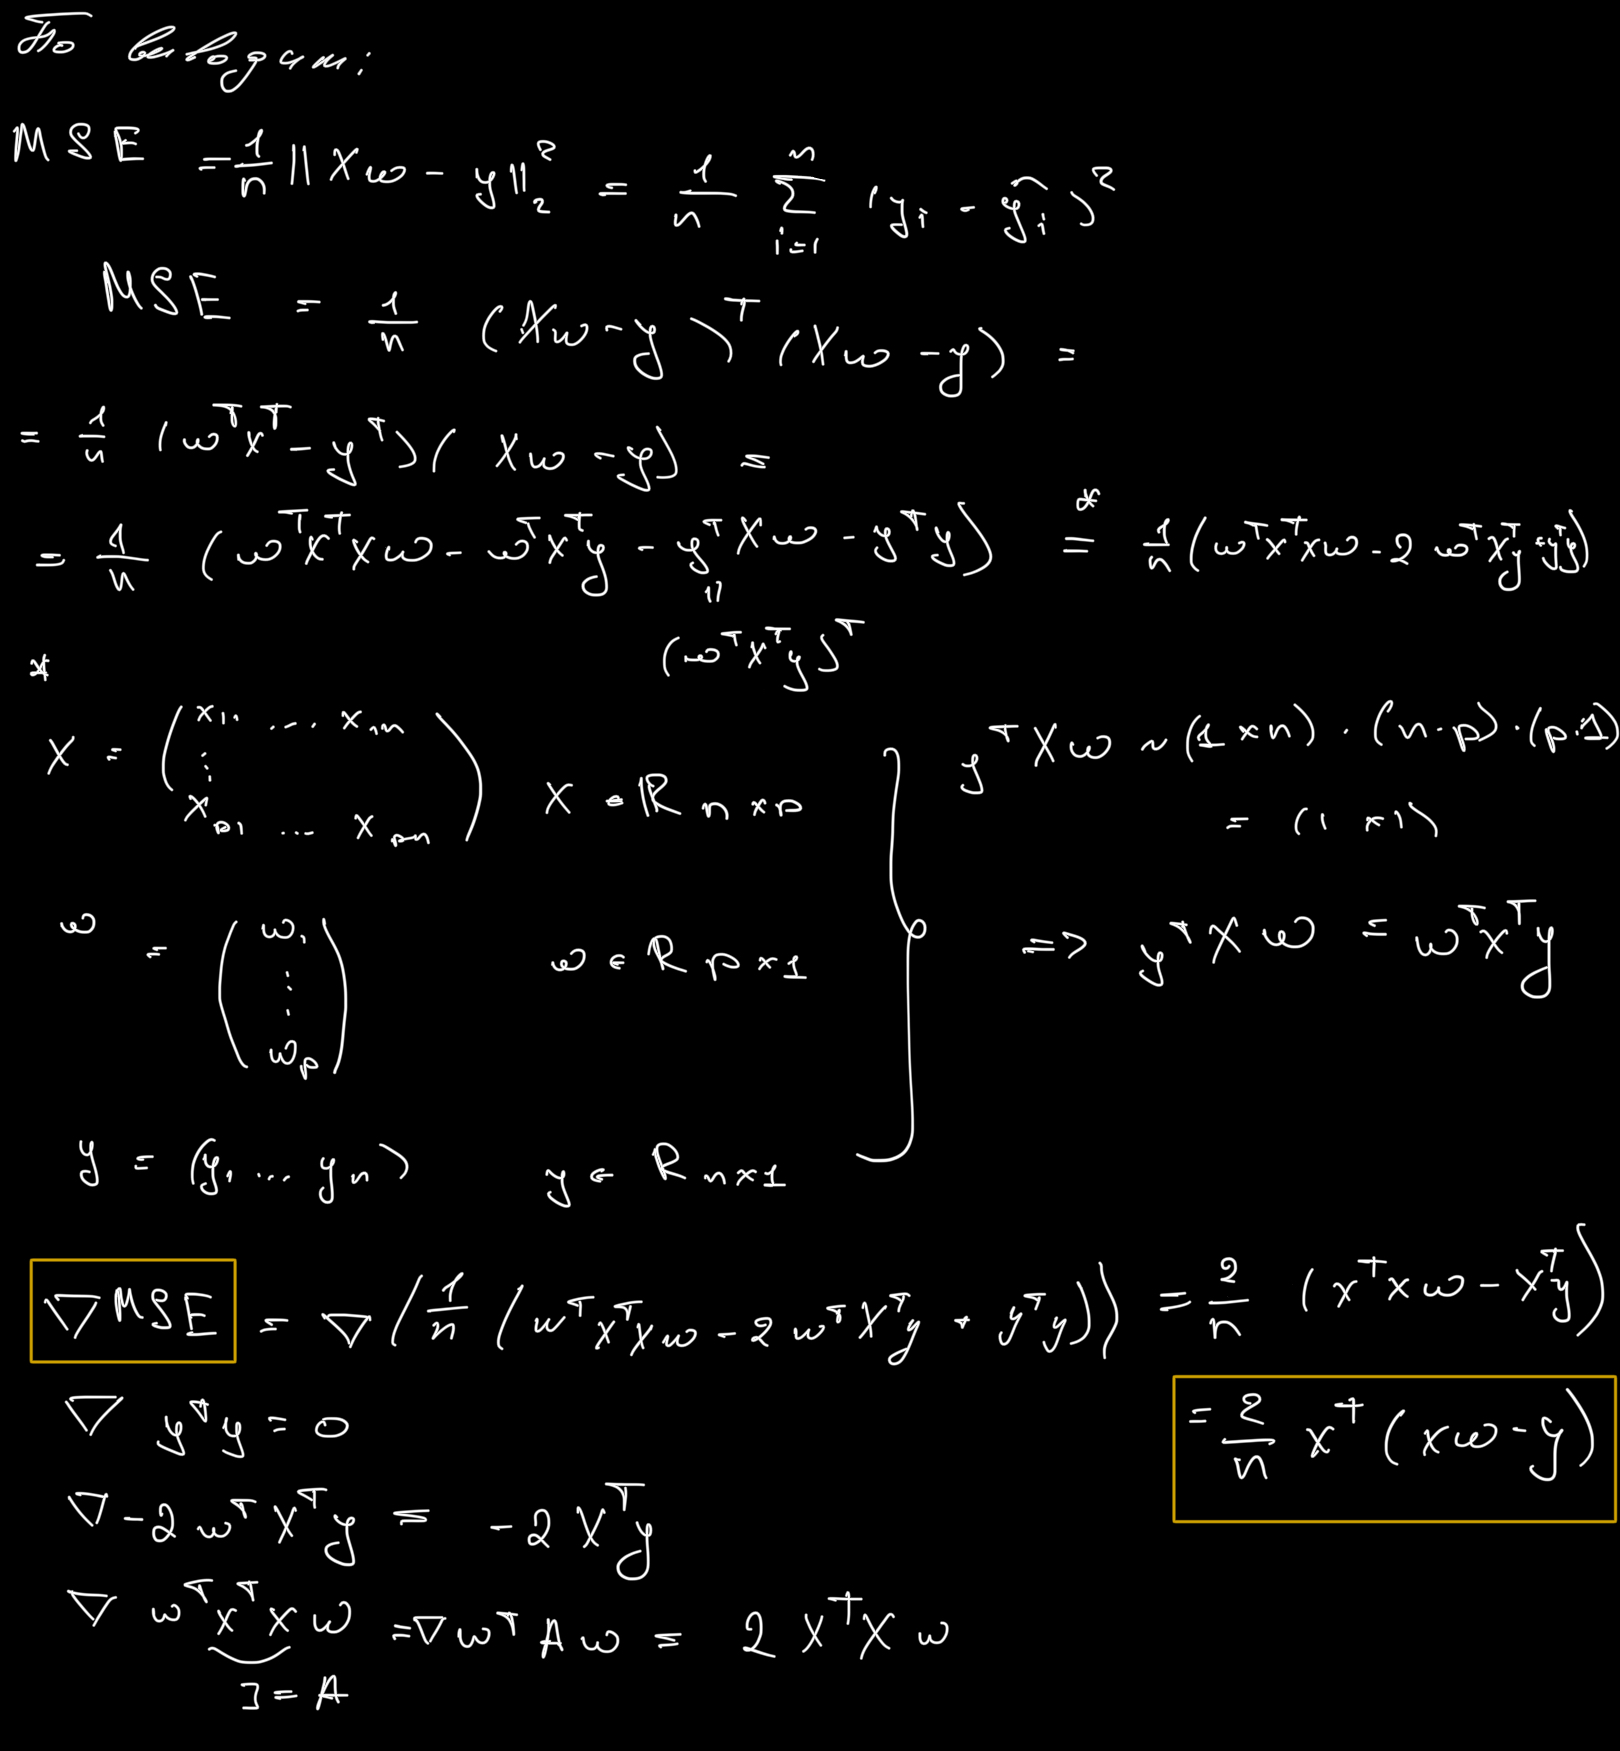 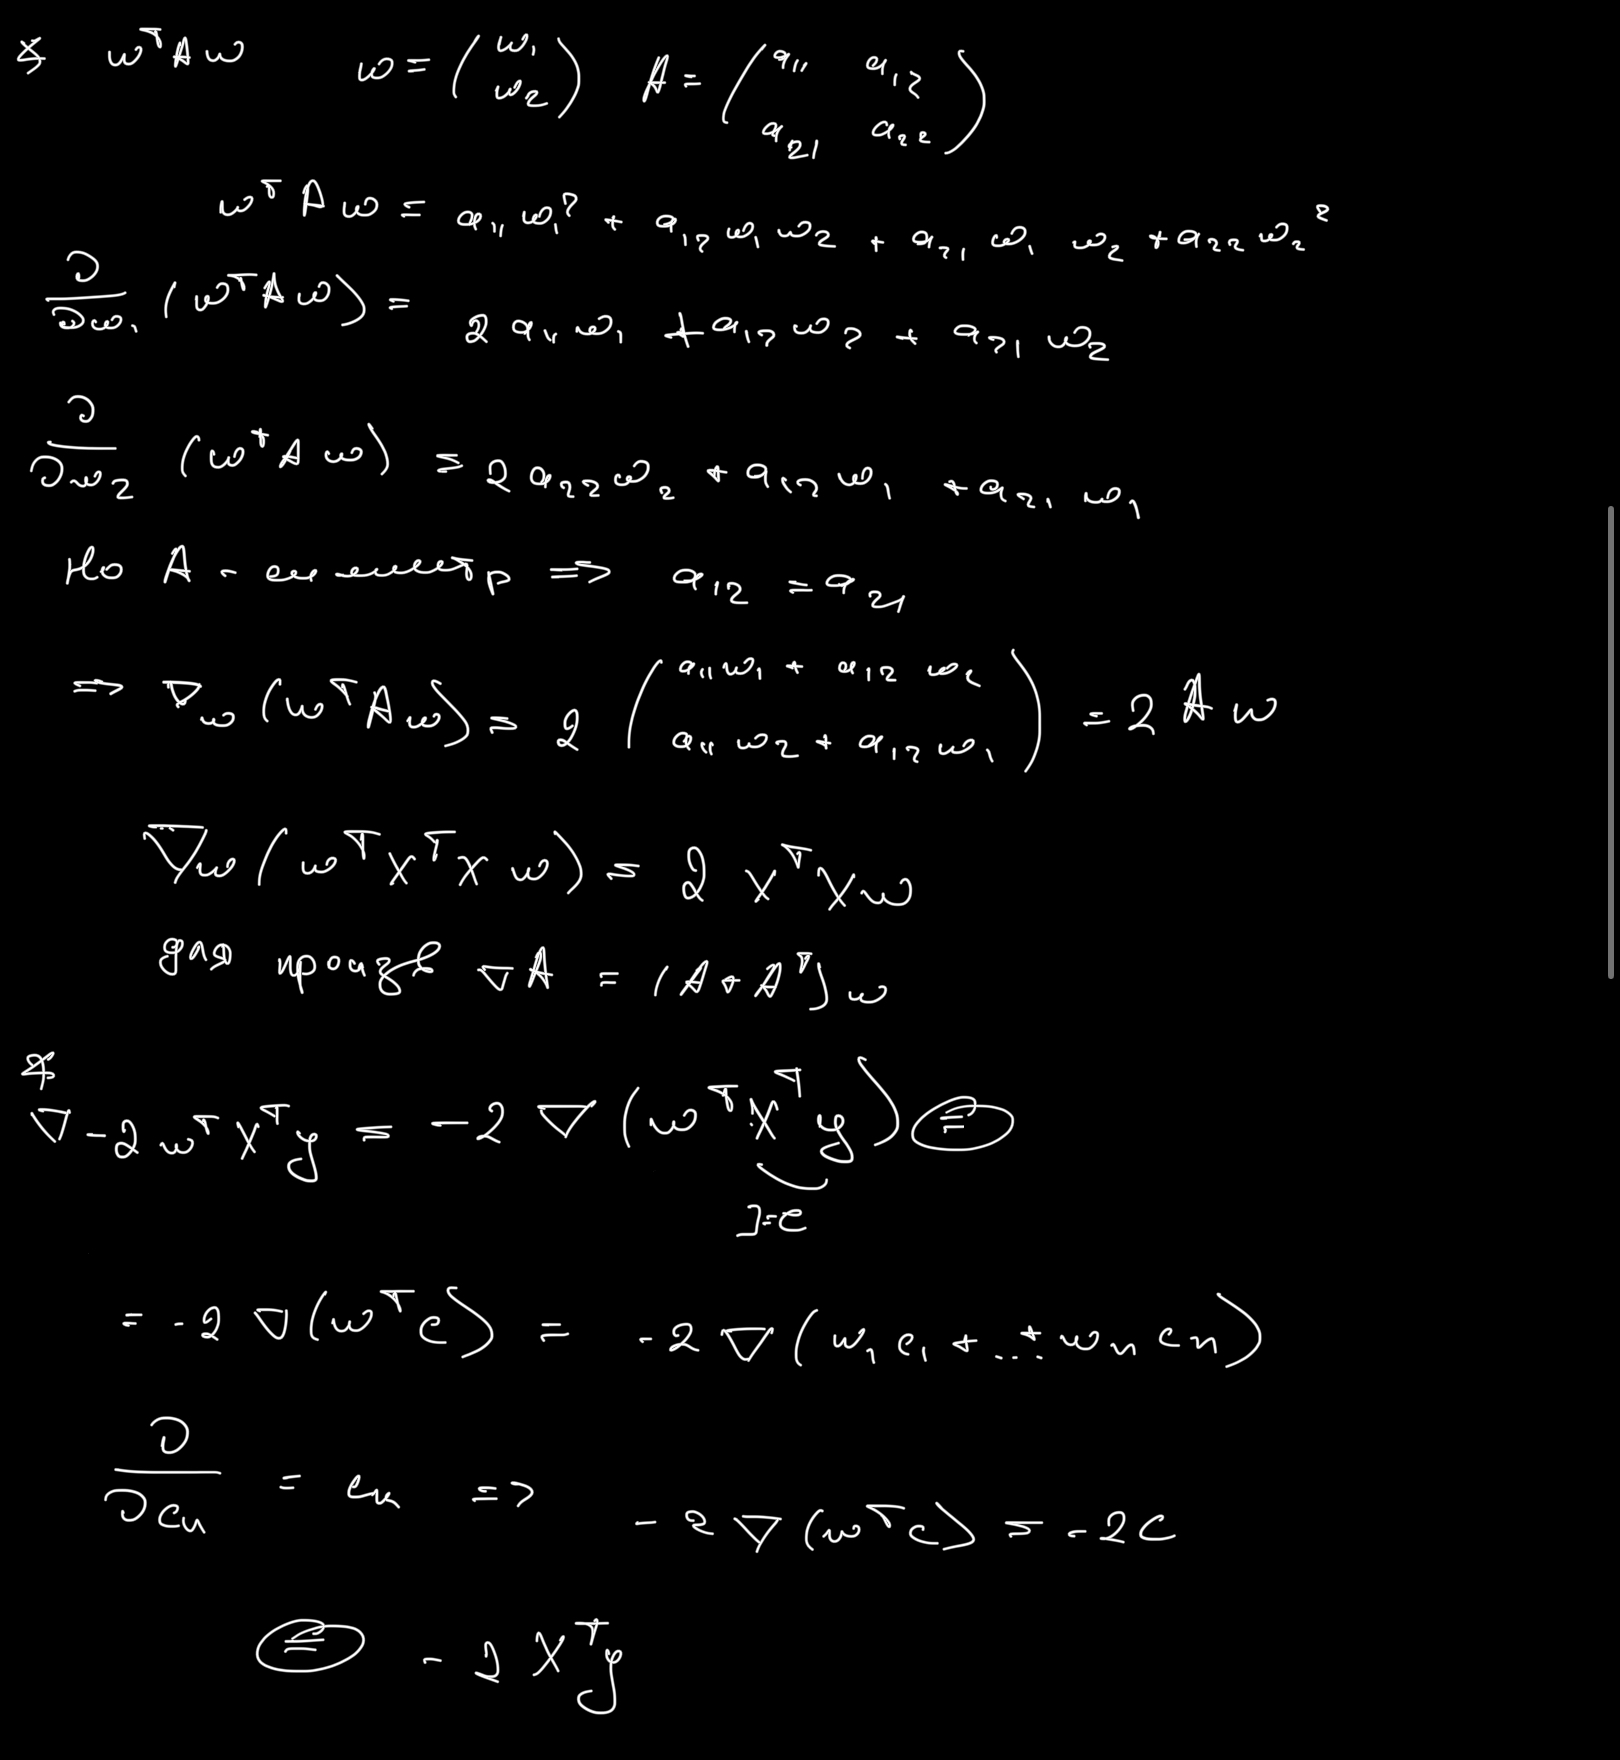

In [14]:
# Используй предобработку из задачи 6
# prep = pipe[:-1]
prep = clone(candidate_pipe[:-1])

X_train_processed = prep.fit_transform(X_train)
X_val_processed = prep.transform(X_val)

def add_bias(X):
    ones = np.ones((X.shape[0], 1))
    return np.hstack([ones, X])

X_train_b = add_bias(prep.transform(X_train))
X_val_b = add_bias(prep.transform(X_val))
alpha = 1.0

# Половина MSE + L1. Не штрафуй свободный член.
def mse_grad(w, X, y):
    n = X.shape[0]
    gradient = (X.T @ (X @ w - y)) / n

    penalty = alpha * np.sign(w)
    penalty[0] = 0

    return gradient + penalty

def gradient_descent(X, y, grad_foo, lr=0.1, n_iter=5000, tol=1e-4, w_init=None):
    """
    grad_foo: функция (w, X, y), возвращающая градиент или субградиент.
    lr: шаг обучения, n_iter: максимальное число обновлений.
    tol: порог нормы градиента для досрочной остановки.
    w_init: начальные веса. Если None, задай прогноз средним y:
        все наклоны равны нулю, свободный член равен np.mean(y).
    Если массив передан, скопируй его, чтобы не изменить предыдущие веса.
    """
    
    # Напиши код здесь. Используй grad_foo и np.linalg.norm.
    if w_init is None:
        w = np.zeros(X.shape[1], dtype=float)
        w[0] = np.mean(y)
    else:
        w = np.array(w_init, dtype=float, copy=True)
    
    for i in range(n_iter):
        gradient = grad_foo(w, X, y)
        
        if np.linalg.norm(gradient) < tol:
            break
        
        w = w - lr * gradient
    
    return w


In [15]:
# Получи веса для MSE
w_gd_mse = gradient_descent(X_train_b, y_train.values, mse_grad, lr=0.001, n_iter=5000, tol=1e-4)

# Функция для получения предсказаний
def predict(X_b, w):
  return X_b @ w

y_min = y_train.min()
# Функция для постобработки ответов. Всё, что меньше минимального значения в датасете, увеличь до минимального
def postprocessing(y_pred):
  return np.maximum(y_pred, y_min)

# Получи предсказания
y_pred_train = postprocessing(predict(X_train_b, w_gd_mse))
y_pred_val = postprocessing(predict(X_val_b, w_gd_mse))

# Получи оценки метрики для train и val
rmsle_train = -scoring_foo(y_train, y_pred_train)
rmsle_valid = -scoring_foo(y_val, y_pred_val)

# Запиши метрики в контейнер и выведи таблицу
res['best_handmade'] = [rmsle_train, rmsle_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmsle_train', 'rmsle_valid'])

# Выведи результат
display(df_res)

# Сравни с Lasso(alpha=alpha, max_iter=10000, tol=1e-6) на тех же признаках.
# Выведи J на train до постобработки и RMSLE на val после неё.
lasso = Lasso(alpha=alpha, max_iter=10000, tol=1e-6)
lasso.fit(X_train_b[:, 1:], y_train)

w_lasso = np.concatenate(([lasso.intercept_], lasso.coef_))

def objective(X_b, y, w, alpha):
    errors = X_b @ w - np.asarray(y)
    return (
        0.5 * np.mean(errors ** 2)
        + alpha * np.sum(np.abs(w[1:]))
    )

df_comparison = pd.DataFrame({
    "J_train": [
        objective(X_train_b, y_train, w_gd_mse, alpha),
        objective(X_train_b, y_train, w_lasso, alpha),
    ],
    "rmsle_valid": [
        -scoring_foo(y_val, postprocessing(X_val_b @ w_gd_mse)),
        -scoring_foo(y_val, postprocessing(X_val_b @ w_lasso)),
    ],
}, index=["Самописный градиентный спуск", "Lasso"])

display(df_comparison)

,rmsle_train,rmsle_valid
base,0.564621,0.567380
MinMaxScaler_Ridge,0.564590,0.567345
MinMaxScaler_Lasso,0.469986,0.468928
MinMaxScaler_ElasticNet,0.898406,0.898806
StandardScaler_Ridge,0.564620,0.567380
StandardScaler_Lasso,0.573146,0.573873
StandardScaler_ElasticNet,0.448930,0.448114
RobustScaler_Ridge,0.564620,0.567379
RobustScaler_Lasso,0.576662,0.577741
RobustScaler_ElasticNet,0.446483,0.446361


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.992e+03, tolerance: 2.188e+03
  model = cd_fast.enet_coordinate_descent(


,J_train,rmsle_valid
Самописный градиентный спуск,127.737635,0.204516
Lasso,120.659521,0.133753


## Задача 9. Реализуй градиентный спуск для RMSLE [2 балла]

Теперь изменим функцию ошибки при обучении. У MSE и RMSLE в общем случае разные минимумы: RMSLE сравнивает ответы в логарифмической шкале. Например, для двух ответов 1 и 9 лучшая константа по MSE равна 5, а по RMSLE примерно 3,47.

Сохраним линейный прогноз $z=Xw$ и постобработку $\hat y_i=\max(y_{min},z_i)$ из предыдущих задач. **Вычисляй RMSLE и её градиент с учётом этой постобработки на каждом шаге обучения**, чтобы логарифм получал допустимые значения.

Для $z_i>y_{min}$ производная прогноза по $w$ равна $x_i$, а для $z_i<y_{min}$ равна нулю. В точке $z_i=y_{min}$ выберем нулевую производную. При нулевой RMSLE также верни нулевой вклад ошибки в градиент, чтобы не делить на ноль. В остальных точках используй правило дифференцирования сложной функции.

Минимизируем

$$J_{log}(w)=RMSLE(y,\hat y)+\alpha_{log}\sum_{j=1}^{p}|w_j|,\qquad \alpha_{log}=10^{-4}.$$

Масштаб RMSLE намного меньше масштаба MSE, поэтому силу штрафа задаём отдельно. Свободный член не штрафуем. Это зафиксированные настройки учебного опыта, без обещания оптимального качества.

**Задание:**

1. Выведи формулу градиента RMSLE с учётом постобработки в LaTeX или на бумаге [1 балл].
2. Реализуй `rmsle_grad` и добавь L1-штраф с коэффициентом `alpha_log` [1 балл].
3. Начни обучение с коэффициентов `w_gd_mse` из задачи 8: передай их через `w_init`, не изменяя исходный массив. Используй тот же алгоритм спуска с новой функцией градиента.
4. Получи прогнозы и сравни RMSLE до и после дообучения. Объясни результат. Улучшение на валидации не гарантируется.

После отсечения функция имеет изломы и плоские участки. Мы используем описанное правило обновления в этих точках, а не предполагаем дифференцируемость всюду.

**Напиши формулу матричного градиента для RMSLE здесь:**

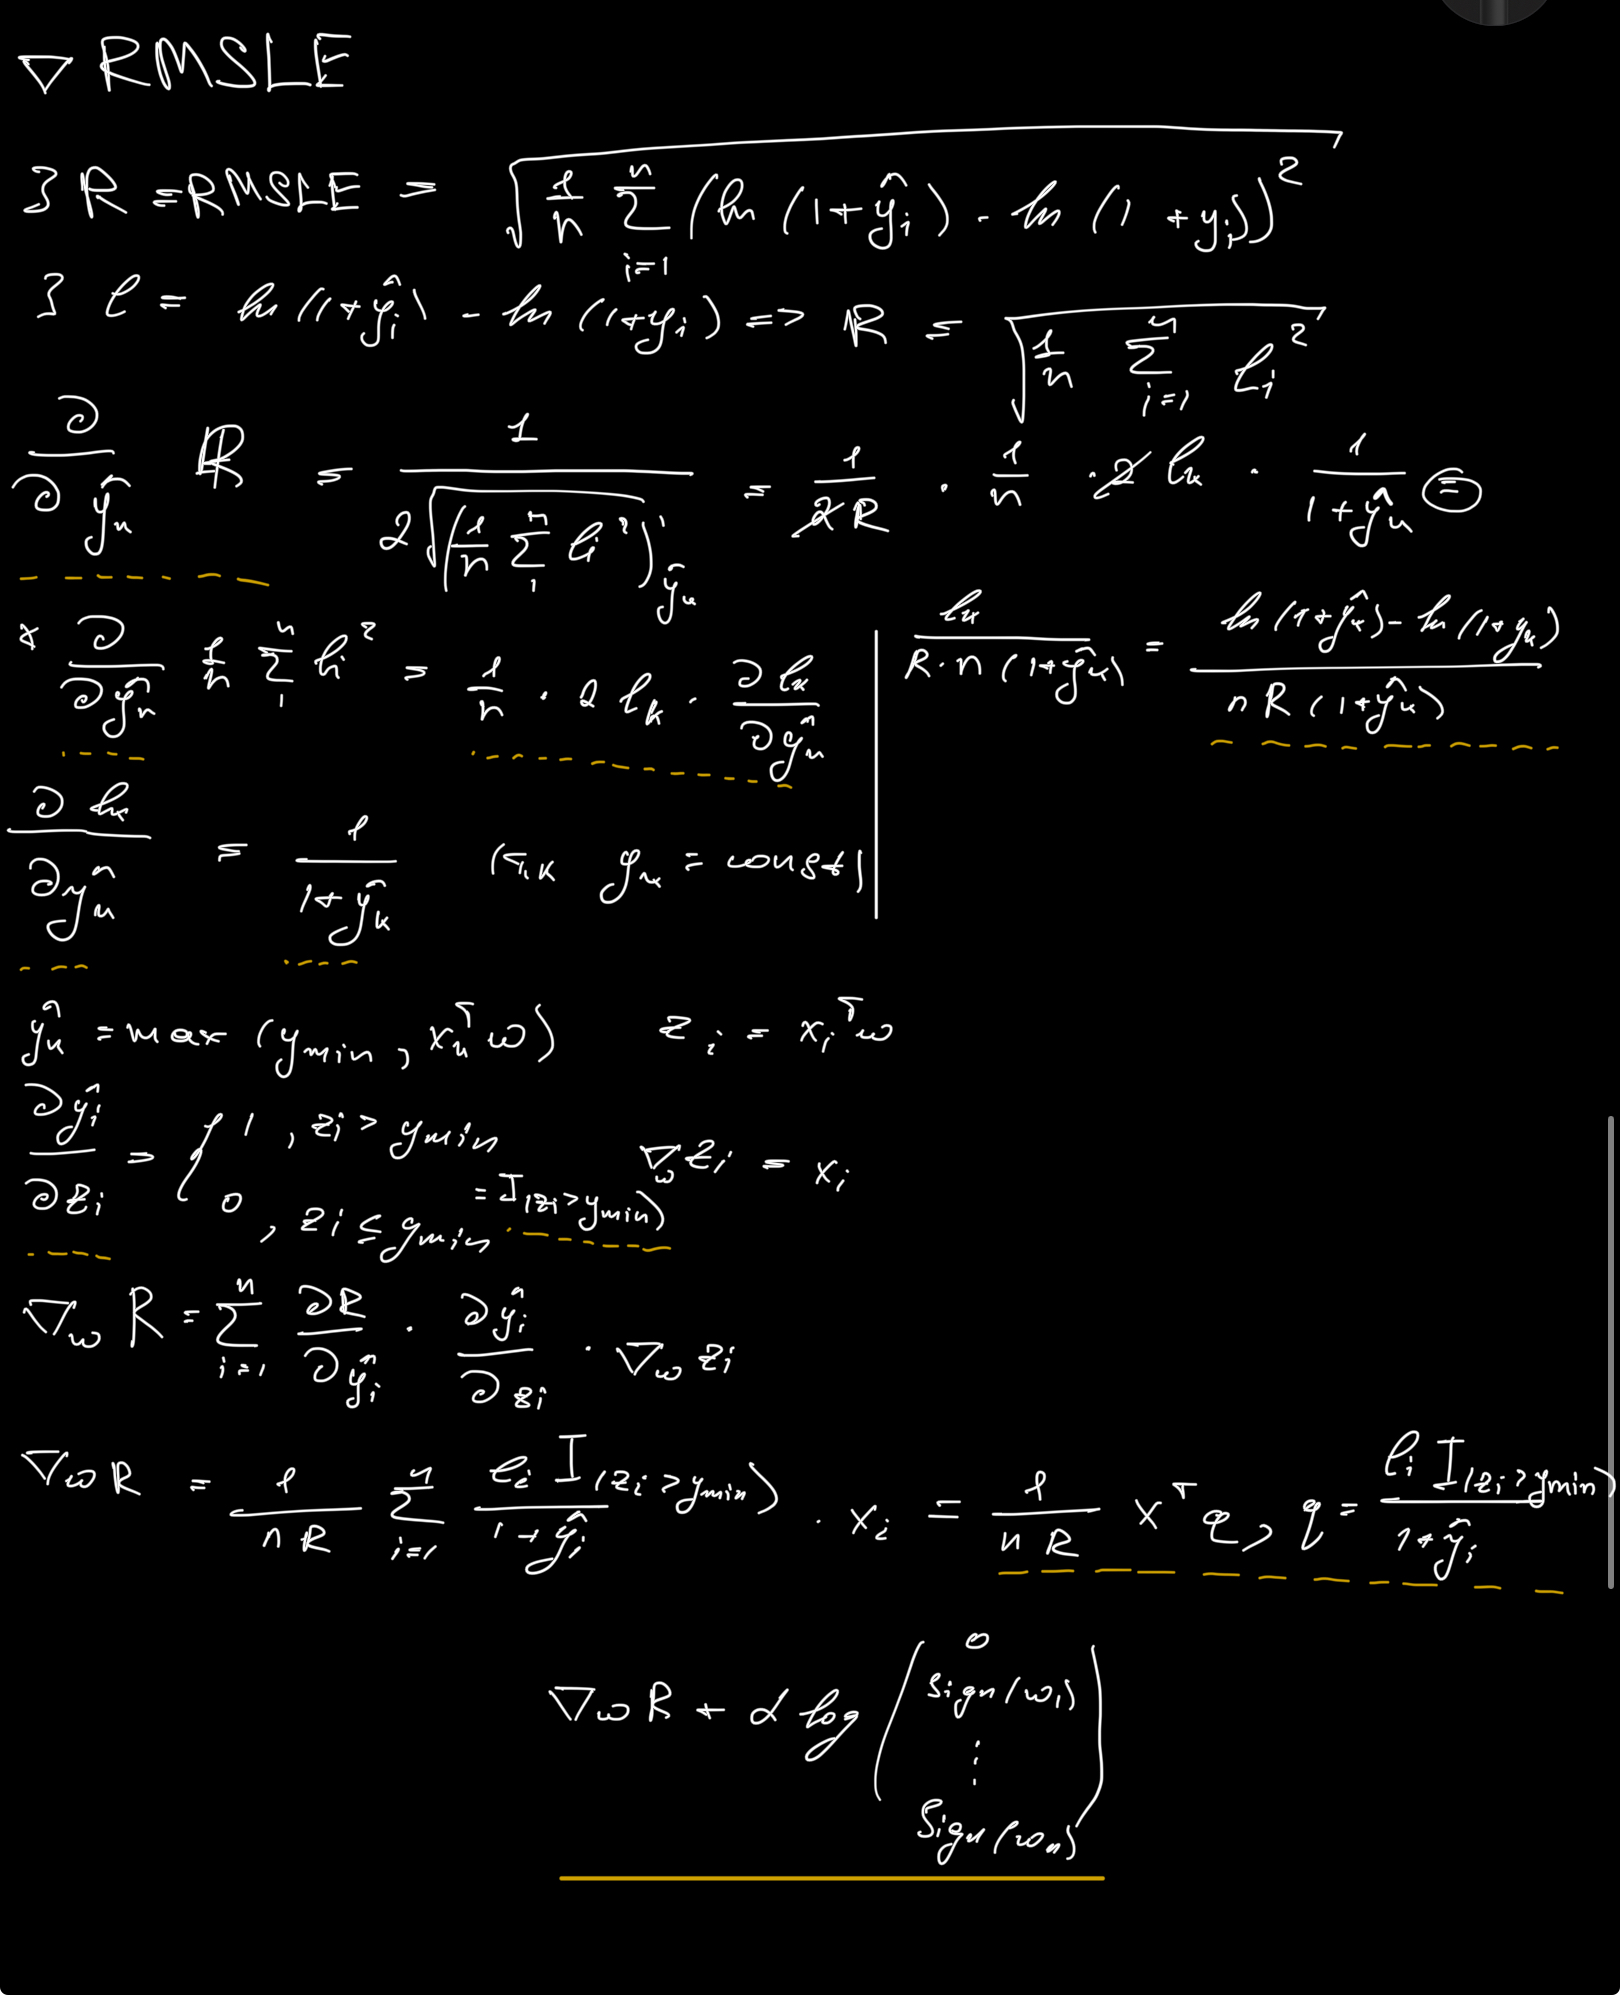

\* Описался: Последний индекс w_p, не w_n 

In [16]:
# RMSLE после постобработки + L1. Свободный член не штрафуем.
alpha_log = 1e-4
def rmsle_grad(w, X, y):
  n = X.shape[0]

  z = X @ w
  y_pred = np.maximum(z, y_min)

  errors = np.log1p(y_pred) - np.log1p(y)
  rmsle = np.sqrt(np.mean(errors ** 2))

  if rmsle == 0:
    gradient = np.zeros_like(w, dtype=float)
  else:
    indicator = z > y_min
    q = errors * indicator / (1 + y_pred)
    gradient = (X.T @ q) / (n * rmsle)

  penalty = alpha_log * np.sign(w)
  penalty[0] = 0

  return gradient + penalty
  

# Получи веса
w_gd_rmsle = gradient_descent(X_train_b, y_train.values, rmsle_grad, lr=1.0, n_iter=5000, tol=1e-5, w_init=w_gd_mse)

# Выведи предсказания
y_pred_train = postprocessing(predict(X_train_b, w_gd_rmsle))
y_pred_val = postprocessing(predict(X_val_b, w_gd_rmsle))

# Получи оценку метрики для train и val
rmsle_train = -scoring_foo(y_train, y_pred_train)
rmsle_valid = -scoring_foo(y_val, y_pred_val)

res['best_handmade_rmsle'] = [rmsle_train, rmsle_valid]
df_res = pd.DataFrame.from_dict(res, orient='index',
                                columns=['rmsle_train', 'rmsle_valid'])

# Выведи результат
df_res

,rmsle_train,rmsle_valid
base,0.564621,0.567380
MinMaxScaler_Ridge,0.564590,0.567345
MinMaxScaler_Lasso,0.469986,0.468928
MinMaxScaler_ElasticNet,0.898406,0.898806
StandardScaler_Ridge,0.564620,0.567380
StandardScaler_Lasso,0.573146,0.573873
StandardScaler_ElasticNet,0.448930,0.448114
RobustScaler_Ridge,0.564620,0.567379
RobustScaler_Lasso,0.576662,0.577741
RobustScaler_ElasticNet,0.446483,0.446361


#### Вывод:
После перехода к RMSLE модель лучше учитывает ошибки. Но при этом одновременно уменьшился коэффициент регуляризации, поэтому весь выигрыш нельзя приписать только смене метрики. Улучшение здесь наблюдается, но в общем случае не гарантируется.